In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as spopt
import numpy.ma as ma
from tqdm import tqdm
import pandas as pd
import glob, os
from astropy.time import Time
import sys
from matplotlib.patches import Rectangle
from matplotlib.patches import Patch

In [2]:
def get_station_colors():
    cols = ['#4dac26', '#377eb8', '#e66101', 'darkorchid', 'black']
    return {'on': cols[0], 'wb': cols[1], 'tr': cols[2], 'st': cols[3], 'fast': cols[4]}

In [3]:
def burst_mjds(database):
    "Function to return the MJDs of bursts splitted for L-band and P-band"
    "For multi-component busts, the TOA is defined as the middle between the peak of the first and the last component."
    
    stats_df = pd.read_csv(database, sep=",", header=0, index_col=0, na_values='NA', engine='python')
    
    #Filter only on entries on arrival time
    stats_df_mjds = stats_df[stats_df["toa_bary_tdb_inf_freq"] != 0]
    
    #The unique identifier is the burst number in column ID
    ids = stats_df_mjds["id"].unique()
    print(ids, len(ids))
    dict_list = []
    
    for burst_id in ids:
        
        stats_df_mjds_id = stats_df_mjds[stats_df_mjds["id"] == burst_id]
        
        #Number of rows: stats_df_mjds_id.shape[0]
        dummy_data = {}
        dummy_data["id"] = burst_id
        if stats_df_mjds_id.shape[0] == 1:
            mjd = stats_df_mjds_id.iloc[0]["toa_bary_tdb_inf_freq"]
            dummy_data["mjd_tdb_inf_freq"] = mjd

        elif stats_df_mjds_id.shape[0] > 1:
            mjd_list = stats_df_mjds_id["toa_bary_tdb_inf_freq"].values
            mjd = (mjd_list[0] + mjd_list[-1]) / 2
            dummy_data["mjd_tdb_inf_freq"] = mjd

        dict_list.append(dummy_data)
    
    df_mjds = pd.DataFrame(dict_list)   
    display(df_mjds)
    
    return df_mjds

df_mjds = burst_mjds(database="../dbs/burst_stats_r117.csv")

['B01-st' 'B02-st' 'B03-st' 'B04-st' 'B05-tr' 'B06-tr' 'B07-st' 'B07-tr'
 'B08-st' 'B09-st' 'B10-st' 'B11-st' 'B12-st' 'B13-st' 'B13-tr' 'B14-wb'
 'B15-tr' 'B15-wb' 'B16-tr' 'B16-wb' 'B17-st' 'B18-st' 'B19-st' 'B20-st'
 'B21-tr' 'B22-wb' 'B23-wb' 'B24-wb' 'B25-st' 'B26-st' 'B27-st' 'B28-st'
 'B29-st' 'B30-st' 'B30-wb' 'B31-st' 'B32-st' 'B33-wb' 'B34-st' 'B35-st'
 'B36-st' 'B37-tr' 'B37-wb' 'B38-st' 'B39-st' 'B40-st' 'B41-st' 'B42-st'
 'B43-st' 'B44-wb' 'B45-wb' 'B46-wb' 'B47-st' 'B48-st' 'B49-st' 'B50-st'
 'B51-wb' 'B52-wb' 'B53-st' 'B53-wb' 'B54-st' 'B55-wb' 'B56-st' 'B57-st'
 'B58-st' 'B59-st' 'B60-st' 'B61-st' 'B62-st' 'B63-st' 'B63-wb' 'B64-st'
 'B64-wb' 'B65-st' 'B66-wb' 'B67-st' 'B68-st' 'B68-wb' 'B69-st' 'B69-wb'
 'B70-wb' 'B71-wb' 'B72-wb' 'B73-st' 'B74-st' 'B75-st' 'B76-st' 'B77-st'
 'B78-st' 'B79-st' 'B80-st' 'B81-wb' 'B82-st' 'B82-wb' 'B83-wb' 'B85-st'
 'B85-wb' 'B86-st' 'B87-st' 'B88-st' 'B89-st' 'B90-st' 'B91-st' 'B92-st'
 'B93-st' 'B94-st' 'B95-st' 'B96-st' 'B97-tr' 'B98-

,id,mjd_tdb_inf_freq
0,B01-st,59867.550262
1,B02-st,59868.720719
2,B03-st,59868.806998
3,B04-st,59868.952065
4,B05-tr,59868.952070
...,...,...
141,B127-wb,59941.687390
142,B128-wb,59941.730176
143,B129-st,59949.882698
144,B131-st,59978.532358


In [4]:
def dummy_maker(telescope, obs_code, df_temp):
    #"Function to make an overview of begin, end and frequency setup per observations"
    #"duplicates are allowed in this df"

    dummy_data = {}
    dummy_data["Telescope"] = telescope
    dummy_data["obs_code"] = obs_code

    dummy_data["mjd_start"] = np.min(df_temp["MJD_start_time"])
    dummy_data["mjd_end"] = np.max(df_temp["MJD_end_time"])

    bandwidth = df_temp["Total_Bandwidth_(MHz)"].values[0]
    nchan = df_temp["Number_of_channels"].values[0]

    #Calculate half the channelwidth
    half_channel_width = (bandwidth/nchan) / 2

    #frequency setup of observation
    dummy_data["bandwidth"] = bandwidth
    #dummy_data["nchan"] = nchan

    dummy_data["cent_f"] = df_temp["Central_freq_(MHz)"].values[0]
    dummy_data["low_c_l"] = df_temp["Low_channel_(MHz)"].values[0] - half_channel_width
    dummy_data["high_c_h"] = df_temp["High_channel_(MHz)"].values[0] + half_channel_width

    rec_time_s = np.sum(df_temp["total_obs_time_s"])
    dummy_data["rec_time_s"] = rec_time_s
    dummy_data["rec_time_m"] = rec_time_s / 60.
    dummy_data["rec_time_h"] = rec_time_s / 3600.
    dummy_data["rec_time_d"] = rec_time_s / (3600. * 24.)
    return dummy_data

In [5]:
def reduce_r117_df(save_bool=False):
    "Function to load in the main R117 dataframe and reduce to a df which can be used for the making of this plot"
    "This smaller dataframe is based per observation instead of per scan"
    "added the multi-freq setup as applied in the R67 paper, it did not change anything, but good to have the code"
    
    big_df = pd.read_csv("../dbs/r117_fullcampaign.csv", sep=",", header=0, index_col=0, \
                            na_values='NA', engine='python')
    
    big_df = big_df.reset_index(drop=True)
    
    dict_list = []

    #list of all telescopes that were used
    #telescopes2 = list(set(big_df["Telescope"]))
    telescopes = big_df["Telescope"].unique()

    for single_telescope in telescopes:
        big_df_telescope = big_df[(big_df["Telescope"] == single_telescope)]
        
        #list of all the observations code that were used for that specific telescope
        observations = list(set(big_df_telescope["scan_name"]))
        
        #observations.sort()
        for s_observation in observations:
            #Create a temp df for a single telescope for a single observation
            #Even though this df only had source r67, I filter on it as a failsave
            df_temp = big_df_telescope[(big_df_telescope["scan_name"] == s_observation)]

            # some runs have more than one frequency setup, need to account for this
            freqs = df_temp["Central_freq_(MHz)"].unique()
            
            #If there are more than 1 frequency setup in a single observations -- switching frequencies
            if len(df_temp["Central_freq_(MHz)"].unique()) > 1 :

                print(f"!!!Splitting the dataframe {s_observation} because of different frequency setup!!!")
                #When the frequency changes it will get a new numbers in the dataframe, this way we can utilze the groupby method of pandas to loop over the differt dfs
                #example: https://stackoverflow.com/questions/64163984/how-to-split-a-dataframe-each-time-a-string-value-changes-in-a-column
                df_temp['group'] = df_temp['Central_freq_(MHz)'].ne(df_temp['Central_freq_(MHz)'].shift()).cumsum()
                df_temp = df_temp.groupby('group')

                for name, df_temp_freqs in df_temp:

                    dummy_data = dummy_maker(single_telescope, s_observation, df_temp_freqs)
                    dict_list.append(dummy_data)

            else:

                dummy_data = dummy_maker(single_telescope, s_observation, df_temp)
                dict_list.append(dummy_data)
            
    df_r117_reduced = pd.DataFrame(dict_list)    
    df_r117_reduced = df_r117_reduced.sort_values(by="mjd_start")
    df_r117_reduced = df_r117_reduced.reset_index(drop=True)
    
    display(df_r117_reduced)
    
    print(df_r117_reduced['low_c_l'].unique())
    print(df_r117_reduced['high_c_h'].unique())
    
    if save_bool == True:
        csv_obs = "../dbs/r117_camp_reduced.csv"
        df_r117_reduced.to_csv(csv_obs, sep=",", header=True, index=True, na_rep='NA')
        print("reduced campaign saved")
    
    return df_r117_reduced

df_r117_reduced = reduce_r117_df(save_bool=False)

,Telescope,obs_code,mjd_start,mjd_end,bandwidth,cent_f,low_c_l,high_c_h,rec_time_s,rec_time_m,rec_time_h,rec_time_d
0,stk,r117_59867_1,59867.366730,59867.430808,98.4375,1381.464844,1332.246094,1430.683594,5536.317002,92.271950,1.537866,0.064078
1,stk,r117_59867_2,59867.525349,59867.650855,98.4375,1381.464844,1332.246094,1430.683594,10843.698408,180.728307,3.012138,0.125506
2,stk,r117_59867_3,59867.650860,59867.775814,98.4375,1381.464844,1332.246094,1430.683594,10796.082573,179.934710,2.998912,0.124955
3,stk,r117_59867_4,59867.775820,59867.859356,98.4375,1381.464844,1332.246094,1430.683594,7217.572304,120.292872,2.004881,0.083537
4,stk,r117_59867_5,59867.887902,59868.014983,98.4375,1381.464844,1332.246094,1430.683594,10979.852508,182.997542,3.049959,0.127082
...,...,...,...,...,...,...,...,...,...,...,...,...
503,stk,r117_59980_340,59980.695273,59980.824386,98.4375,1381.464844,1332.246094,1430.683594,11155.338690,185.922312,3.098705,0.129113
504,wb,p11785,59981.319595,59981.817210,64.0000,332.000000,300.000000,364.000000,41210.371061,686.839518,11.447325,0.476972
505,tr,f22l45,59981.562593,59981.848611,128.0000,1414.000000,1350.000000,1478.000000,23470.919957,391.181999,6.519700,0.271654
506,wb,p11786,59982.316806,59982.814454,64.0000,332.000000,300.000000,364.000000,33512.770559,558.546176,9.309103,0.387879


[1332.24609375 1207.         1350.         4580.         4798.49
 1290.         4600.          300.        ]
[1430.68359375 1335.         1478.         4836.         5054.49
 1546.         4728.          364.        ]


In [6]:
colours_stations = get_station_colors()

In [27]:
def observing_plot(df_reduced, df_mjd, colours):
    
    # set width and height of figure in inches
    width, height = 20, 25
    fig, (ax1, ax2, ax3, ax4, \
          ax5, ax6, ax7, ax8, \
          ax9, ax10, ax11, ax12, \
          ax13, ax14, ax15) = plt.subplots(15, 1, figsize=(width, height), sharex=False,
        gridspec_kw={'height_ratios': (1/0.92, 1, 1/3.4, 0.4, \
                                       1/0.92, 1, 1/3.4, 0.4, \
                                       1/0.92, 1, 1/3.64, 0.4, \
                                       1/0.92, 1, 1/3.64, )})
    #ratio= bandwidth_band1 / bandwidth_band2 379/510=0.75 
    #For c-band, making it less important, since Lband is where we have detections. by ~20%

    fig.subplots_adjust(hspace=0)
    
    #Setting of the spacing of the plots
    space = 20
    c_low = 4580
    c_high = 5050
    l_low = 1207
    l_high = 1546
    
    c_axes = [ax1,ax5,ax9,ax13]
    l_axes = [ax2,ax6,ax10,ax14]
    p_axes = [ax3,ax7,ax11,ax15]
    inv_axes = [ax4,ax8,ax12]
    
    for ax in c_axes:
        ax.set_ylim(c_low-space, c_high+space)
        ax.set_yticks([4600, 4800, 5000])
        ax.spines['bottom'].set_visible(False)
        ax.tick_params(labeltop=False)
        ax.xaxis.tick_top()
        
    for ax in l_axes:
        ax.set_ylim(l_low-space,l_high+space)
        ax.set_yticks([1200, 1350, 1500])
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.tick_params(labeltop=False)
        #ax.tick_params(axis='x', length=0)
        ax.tick_params(labelbottom=False,bottom=False)
        
    for ax in p_axes:
        ax.set_ylim(300-space,364+space)
        ax.set_yticks([330])
        ax.spines['top'].set_visible(False)
        ax.tick_params(labeltop=False)
        ax.xaxis.tick_bottom()
        
    ax3.set_ylim(290-space,364+space)
    ax7.set_ylim(290-space,364+space)
    
    for ax in inv_axes:
        ax.set_visible(False)

    fig.text(0.06, 0.5, 'Frequency (MHz)', va='center', rotation='vertical', fontsize=28)
    ax15.set_xlabel("Time (MJD)", fontsize=28)
    
    for ax in [*c_axes, *l_axes, *p_axes]:
        ax.tick_params(labelsize=14)

    # Draw the diagonal lines to show broken axes
    # See example: https://matplotlib.org/stable/gallery/subplots_axes_and_figures/broken_axis.html
    # mew 2 is for thickness
    d = 0  # proportion of vertical to horizontal extent of the slanted line (0 is horizontal)
    kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=2, clip_on=False)
    ax1.plot([0, 1], [0, 0], transform=ax1.transAxes, **kwargs)
    ax2.plot([1, 0], [1, 1], transform=ax2.transAxes, **kwargs)
    ax2.plot([0, 1], [0, 0], transform=ax2.transAxes, **kwargs)
    ax3.plot([1, 0], [1, 1], transform=ax3.transAxes, **kwargs)

    ax5.plot([0, 1], [0, 0], transform=ax5.transAxes, **kwargs)
    ax6.plot([1, 0], [1, 1], transform=ax6.transAxes, **kwargs)
    ax6.plot([0, 1], [0, 0], transform=ax6.transAxes, **kwargs)
    ax7.plot([1, 0], [1, 1], transform=ax7.transAxes, **kwargs)
    
    ax9.plot([0, 1], [0, 0], transform=ax9.transAxes, **kwargs)
    ax10.plot([1, 0], [1, 1], transform=ax10.transAxes, **kwargs)
    ax10.plot([0, 1], [0, 0], transform=ax10.transAxes, **kwargs)
    ax11.plot([1, 0], [1, 1], transform=ax11.transAxes, **kwargs)
    
    ax13.plot([0, 1], [0, 0], transform=ax13.transAxes, **kwargs)
    ax14.plot([1, 0], [1, 1], transform=ax14.transAxes, **kwargs)
    ax14.plot([0, 1], [0, 0], transform=ax14.transAxes, **kwargs)
    ax15.plot([1, 0], [1, 1], transform=ax15.transAxes, **kwargs)
    
    fig.subplots_adjust(hspace=0.1)
    legend_elements = [Patch(facecolor=colours['on'], label='Onsala'),
                       Patch(facecolor=colours['tr'], label=r'Toru$\mathrm{\'n}$'),
                       Patch(facecolor=colours['st'], label='Stockert'),
                       Patch(facecolor=colours['wb'], label='Westerbork')]
    ax1.legend(handles=legend_elements, loc='upper right', fontsize=18)
    
    for i in tqdm(range(len(df_reduced["mjd_start"]))):
        tele = df_reduced["Telescope"][i]
        obs_code = df_reduced["obs_code"][i]
        mjd_s = df_reduced["mjd_start"][i]
        mjd_e = df_reduced["mjd_end"][i]
        low_c = df_reduced["low_c_l"][i]
        high_c = df_reduced["high_c_h"][i]
        bandwidth = df_reduced["bandwidth"][i]
        obs_time_d = df_reduced["rec_time_d"][i]
        if tele == "tr":
            lab, cc = "Torun", colours['tr']
        if tele == "stk":
            lab, cc = "Stockert", colours['st']
        if tele == "wb":
            lab, cc = "Westerbork", colours['wb']
        if tele == "o8":
            lab, cc = "Onsala", colours['on']
        #Draw the figure in all three axes in one panel
        for ax in [*c_axes, *l_axes, *p_axes]:
            rect = Rectangle((mjd_s, low_c), obs_time_d, height=bandwidth,
                             facecolor=cc, lw=0.0, edgecolor='k')
            ax.add_patch(rect)
            
    ax3.get_shared_x_axes().join(ax1, ax2, ax3)
    ax7.get_shared_x_axes().join(ax5, ax6, ax7)
    ax11.get_shared_x_axes().join(ax9, ax10, ax11)
    ax15.get_shared_x_axes().join(ax13, ax14, ax15)
    
    start_mjd = 59867
    end_mjd = 59983
#     split = ((end_mjd ) - start_mjd) / 4
#     d_bound_1 = start_mjd + split
#     d_bound_2 = d_bound_1 + split
#     d_bound_3 = d_bound_2 + split
#    print(d_bound_1,d_bound_2,d_bound_3)
    d_bound_1 = 59889
    d_bound_2 = 59911
    d_bound_3 = 59945

    
    mjd_1 = df_mjds[df_mjds['mjd_tdb_inf_freq'].between(start_mjd, d_bound_1)]['mjd_tdb_inf_freq'].values
    mjd_2 = df_mjds[df_mjds['mjd_tdb_inf_freq'].between(d_bound_1, d_bound_2)]['mjd_tdb_inf_freq'].values
    mjd_3 = df_mjds[df_mjds['mjd_tdb_inf_freq'].between(d_bound_2, d_bound_3)]['mjd_tdb_inf_freq'].values
    mjd_4 = df_mjds[df_mjds['mjd_tdb_inf_freq'].between(d_bound_3, end_mjd)]['mjd_tdb_inf_freq'].values

    #line kwargs
    kwargs = dict(ymax=1,clip_on=False, ls='--', color='k', lw=0.8)
    for burst_mjd in mjd_1:
        #ymix -1.2 is needed to draw in the empty spaces between plots
        ax1.axvline(x=burst_mjd, ymin=-1.2, **kwargs)
        ax2.axvline(x=burst_mjd, ymin=0, **kwargs)
        ax3.axvline(x=burst_mjd, ymin=0, **kwargs)

    for burst_mjd in mjd_2:
        ax5.axvline(x=burst_mjd, ymin=-1.2, **kwargs)
        ax6.axvline(x=burst_mjd, ymin=0, **kwargs)
        ax7.axvline(x=burst_mjd, ymin=0, **kwargs)

    for burst_mjd in mjd_3:
        
        #All pband bursts were detected between these 2 MJDs, one burst was detected on L-band
        #So one exception on this rule -- suck it future hardcoded haters, this is the easiest method
        if 59922<burst_mjd<59942 and burst_mjd !=59925.00963282705:
            color_l='red'
            
        else:
            color_l='k'
        ax9.axvline(x=burst_mjd, ymax=1, ymin=-1.2, clip_on=False, ls='--', color=color_l, lw=0.8)
        ax10.axvline(x=burst_mjd, ymax=1, ymin=0, clip_on=False, ls='--', color=color_l, lw=0.8)
        ax11.axvline(x=burst_mjd, ymax=1, ymin=0, clip_on=False, ls='--', color=color_l, lw=0.8)
        
    for burst_mjd in mjd_4:
        ax13.axvline(x=burst_mjd, ymin=-1.2, **kwargs)
        ax14.axvline(x=burst_mjd, ymin=0, **kwargs)
        ax15.axvline(x=burst_mjd, ymin=0, **kwargs)
        
    #Set the limits on the plots
    ax1.set_xlim(start_mjd,d_bound_1)
    ax5.set_xlim(d_bound_1,d_bound_2)
    ax9.set_xlim(d_bound_2,d_bound_3)
    ax13.set_xlim(d_bound_3,end_mjd)
    
    #Set specific dates on xticks
    ax1.set_xticks([start_mjd, start_mjd+(d_bound_1-start_mjd)/2, d_bound_1])
    ax3.set_xticks([start_mjd, start_mjd+(d_bound_1-start_mjd)/2, d_bound_1])

    ax5.set_xticks([d_bound_1,d_bound_1+(d_bound_2-d_bound_1)/2,d_bound_2])
    ax7.set_xticks([d_bound_1,d_bound_1+(d_bound_2-d_bound_1)/2,d_bound_2])

    ax9.set_xticks([d_bound_2,d_bound_2+(d_bound_3-d_bound_2)/2,d_bound_3])
    ax11.set_xticks([d_bound_2,d_bound_2+(d_bound_3-d_bound_2)/2,d_bound_3])
    
    ax13.set_xticks([d_bound_3,d_bound_3+(end_mjd-d_bound_3)/2,end_mjd])
    ax15.set_xticks([d_bound_3,d_bound_3+(end_mjd-d_bound_3)/2,end_mjd])
    
    ##Panels for the overlap for the energy distribution
    # 59869 and 59910
    yminvspan=0
    ymaxvspan=0.2
    ax3.axvspan(xmin=59869, xmax=59910, ymin=yminvspan, ymax=ymaxvspan, alpha=0.5, color='black')
    ax7.axvspan(xmin=59869, xmax=59910, ymin=yminvspan, ymax=ymaxvspan, alpha=0.5, color='black')
    
    for ax in [*c_axes, *l_axes, *p_axes]: 
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=7, width=2, labelsize=20)
            ax.tick_params(axis='x', which='major', direction='out', length=7, width=2, labelsize=20)
    
    for ax in c_axes:
        times_top = ax.get_xticks()
        t_t = Time(times_top, format='mjd', scale='utc')
        mjd_isot_t = t_t.to_value('isot', 'date')
        ax.set_xticklabels(mjd_isot_t)
        ax.tick_params(labelrotation=0)

    plt.savefig("../plots/Observingplot_r117_v2.pdf", bbox_inches='tight')
    plt.savefig("../Observingplot_4panels" + ".png", bbox_inches='tight',
               facecolor='white', transparent=False, dpi=600)

    plt.show()

100%|██████████| 508/508 [00:04<00:00, 108.72it/s]


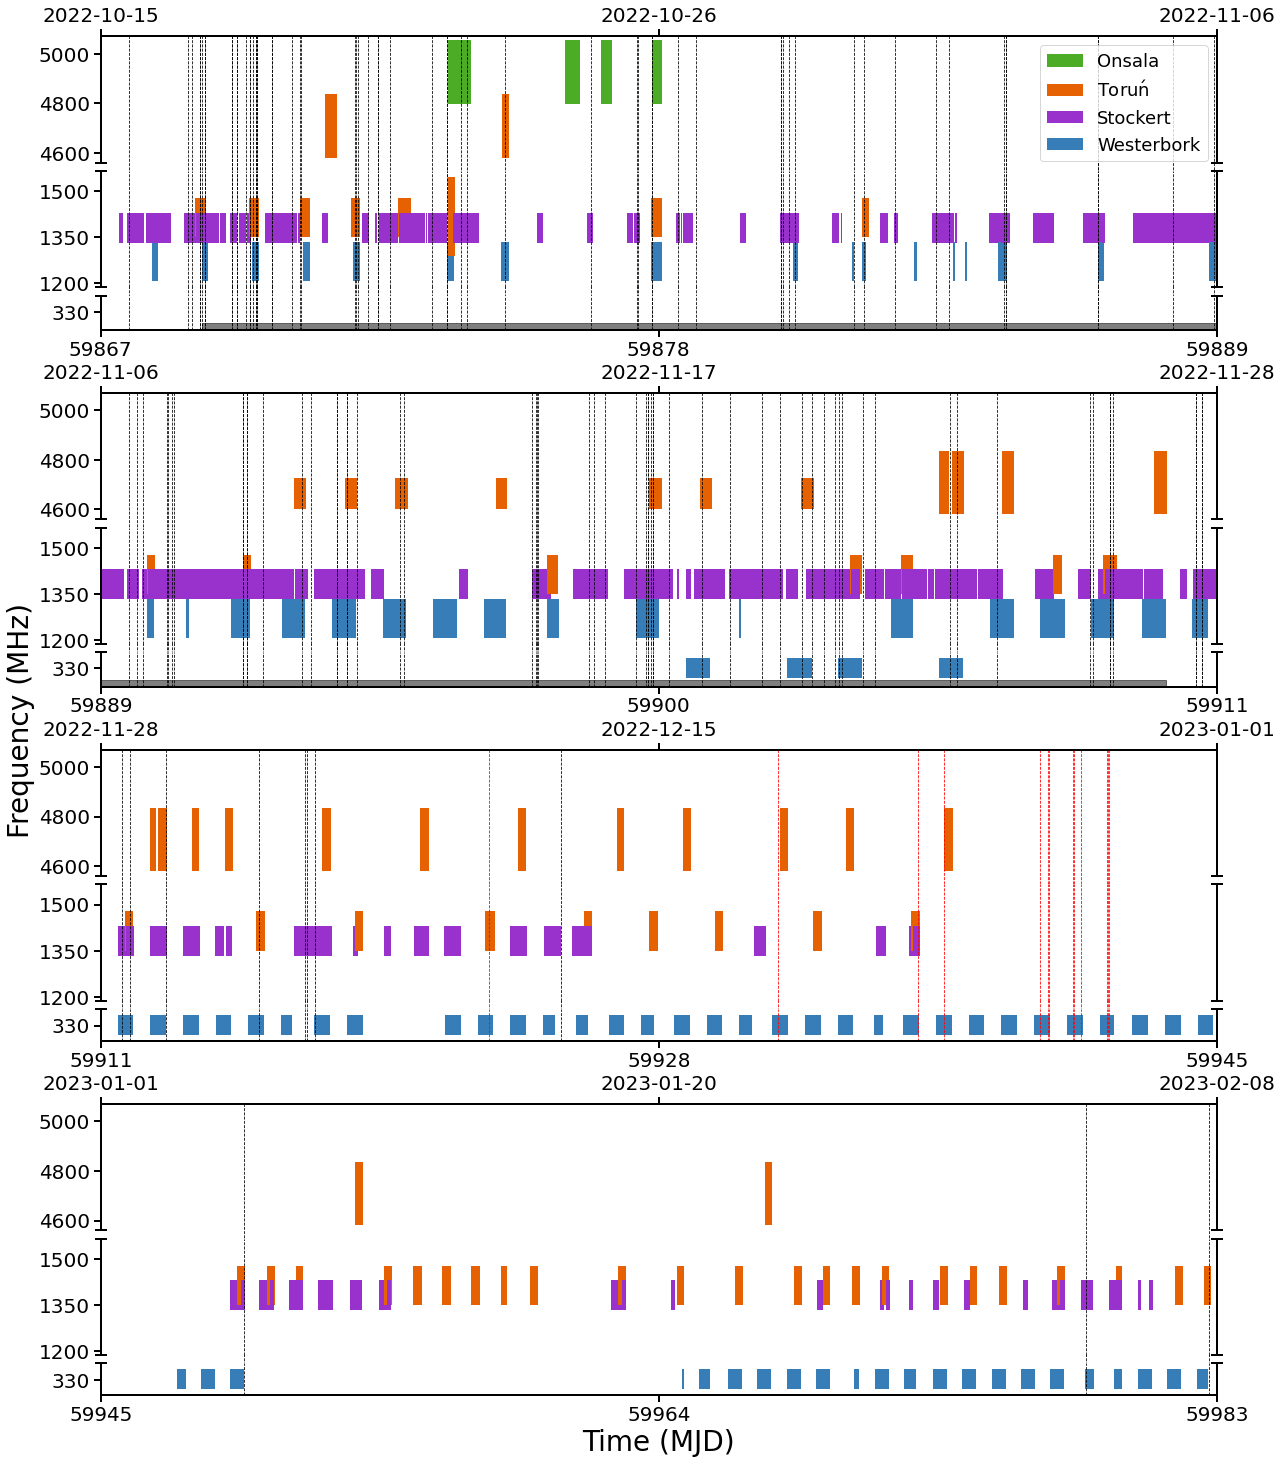

In [28]:
observing_plot(df_reduced=df_r117_reduced, df_mjd=df_mjds, colours=colours_stations)